smote is a synthetic minority oversampling technique

1. imbalanced datasets - minority class has fewer instances than the majority class 
eg: no's are less than the yes's

2. generating synthetic instances of minority class(no's) by interpolating between existing instances.
eg: interpolationg between two points in graph  (*       *),it creates synthetic instances (artificial datapoints around them)-->('*' * * * '*') 


In [1]:
from sklearn.datasets import make_classification


In [3]:
x,y = make_classification(n_samples = 1000,n_features = 2,n_clusters_per_class=1,weights = [0.90] #here weights are like one class should be 90 percentage more than the other classs
                    ,n_redundant=0 #here redundant is the info that is already available in other features
                    ,random_state=12
                     )
#get two arrays which were x,y

In [4]:
import pandas as pd

In [6]:
df1 = pd.DataFrame(x,columns=['f1','f2'])
df2 = pd.DataFrame(y,columns=['target'])
final_df = pd.concat([df1,df2],axis=1)

In [7]:
final_df.shape

(1000, 3)

In [8]:
final_df.head()

,f1,f2,target
0,-0.762898,-0.706808,0
1,-1.075436,-1.051162,0
2,-0.610115,-0.909802,0
3,-2.023284,-0.428945,1
4,-0.812921,-1.316206,0


In [9]:
final_df['target'].value_counts()

target
0    900
1    100
Name: count, dtype: int64

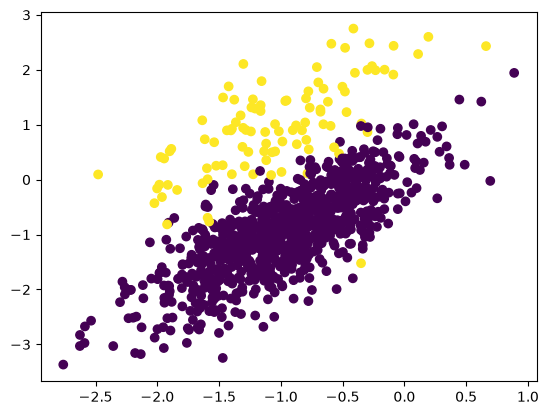

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(final_df['f1'],final_df['f2'],c=final_df['target']) #it adds colors to the x and y axis based on target

In [11]:
#to apply swot there is a library which is a imlearn
#we have to install that library

!pip install imblearn

     -------------------------------------- 236.1/236.1 kB 4.9 MB/s eta 0:00:00



[notice] A new release of pip available: 22.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from imblearn.over_sampling import SMOTE

In [14]:
#transform the dataset
oversample = SMOTE()  #creating an object for smote class
x,y = oversample.fit_resample(final_df[['f1','f2']],final_df['target'])
#fit_sample does two things
#1. fit : learns feature sapce relations between samples to generate synthetic minority samples
#2. resample : generates sysnthetic samples and returns the balanced feature datset with correspnding labels

In [15]:
x.shape

(1800, 2)

In [16]:
y.shape

(1800,)

In [18]:
len(y[y==0])

900

In [19]:
len(y[y==1])

900

In [20]:
df1 = pd.DataFrame(x,columns=['f1','f2'])
df2 = pd.DataFrame(y,columns=['target'])
oversampled_df = pd.concat([df1,df2],axis =1)

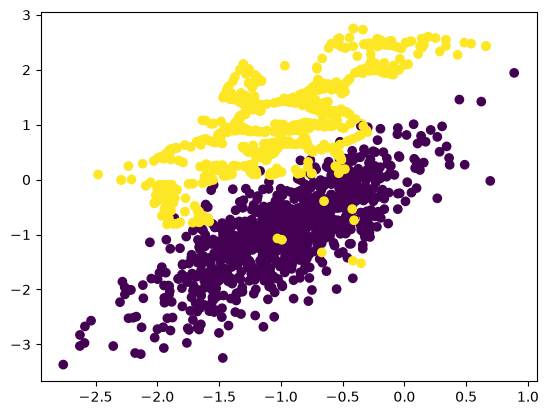

In [21]:
plt.scatter(oversampled_df['f1'],oversampled_df['f2'],c=oversampled_df['target'])